# 读数不完美时：单位、边界和异常点

In [1]:
from pathlib import Path
import sys
root = Path.cwd().resolve()
while not (root / 'lsq').is_dir():
    if root == root.parent:
        raise RuntimeError('Run inside the repository')
    root = root.parent
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import least_squares
from lsq import (finite_difference, whiten, gauss_newton,
                 levenberg_marquardt, dogleg, recursive_update)
np.set_printoptions(precision=5, suppress=True)
plt.rcParams.update({'figure.figsize': (6.4, 3.3), 'font.size': 10,
                     'axes.grid': True, 'savefig.dpi': 130})

前面的读数只是轻轻抖动。实际工作中，可能还混进一条通信错误的记录，某个参数不能为负，几个参数的数值大小又差了几千倍。换一个求解器名称，不能同时解决所有问题。

本章先用**人为加入异常点的合成数据**练手，学习面对真实数据时要做哪些检查。我们没有在这里采集真实仪器数据。

## 先把旋钮的刻度说清楚

调时间常数 1 秒和调长度 1 毫米，不一定是同样大的改变。**参数缩放**是给每个参数一个合理的参考刻度，使“调一格”表达相近的实际变化程度。代码的 `x_scale=[2.,1.,.5]` 就提供这样的尺度。

公式上令 $x=Sz$，其中 $S$ 的对角线放各参数尺度，于是 $J_z=J_xS$。白化处理的是不同读数的误差尺度，参数缩放处理的是不同旋钮的刻度；一个主要作用于行，一个主要作用于列，不能互相替代。

## 有些位置根本不允许走

下降速率若按模型要求非负，就明确设置下界 0。这叫**边界约束**。本例用 SciPy 的 `trf`，它支持上下界。不能先算任意一步、最后随意裁剪，再认为仍是同一种优化过程：裁剪可能改变方向和原先的改善预测。SciPy 的 `lm` 不支持边界，且只支持普通平方损失。

## 不让几个离谱读数牵着整条线走

**稳健损失**是一种评分规则：小偏差仍认真计分，特别大的偏差不再按平方那么快地涨分。像开会时仍听取离群意见，但不让一句特别响的话压过所有证据。

下面在第 5、18、30 号数组位置人为加入大偏差，比较普通平方评分与 `soft_l1`。图中 `contaminated data` 是混入异常值的读数，`squared loss` 是普通拟合，`soft-L1` 是稳健拟合。先猜哪条曲线更少追着那几个孤立点跑。

需要查公式时：标准化平方残差为 $s$ 时，soft-L1 用 $\rho(s)=2(\sqrt{1+s}-1)$。尺度 `f_scale` 决定多大的原始残差开始明显降低影响，本例设为正常噪声 `.04`。这个尺度应有测量依据，不能只为画出喜欢的线而挑选。

truth: [2.5 0.8 0.4] ordinary: [2.57621 0.85852 0.44442] robust: [2.48872 0.7942  0.39657]


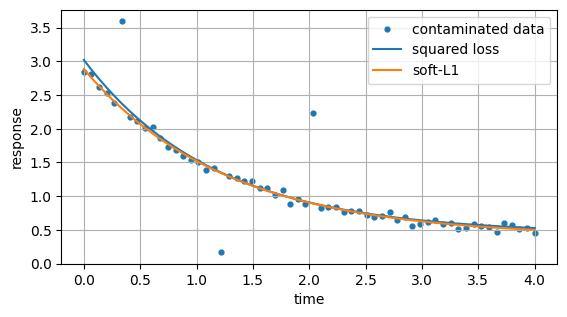

In [2]:
rng = np.random.default_rng(112)
t = np.linspace(0,4,60); sigma=.04
truth = np.array([2.5,.8,.4])
y = truth[0]*np.exp(-truth[1]*t)+truth[2]+rng.normal(0,sigma,len(t))
y[[5,18,30]] += [1.2,-1.1,1.3]
def residual(p):
    return p[0]*np.exp(-p[1]*t)+p[2]-y
bounds = ([0.,0.,0.],[6.,4.,2.])
ordinary = least_squares(residual,[2.,.5,.2],bounds=bounds,method='trf')
robust = least_squares(residual,[2.,.5,.2],bounds=bounds,
                       method='trf',loss='soft_l1',f_scale=sigma,
                       x_scale=[2.,1.,.5])
print('truth:',truth,'ordinary:',ordinary.x,'robust:',robust.x)
plt.scatter(t,y,s=12,label='contaminated data')
plt.plot(t,residual(ordinary.x)+y,label='squared loss')
plt.plot(t,residual(robust.x)+y,label='soft-L1')
plt.xlabel('time');plt.ylabel('response');plt.legend();plt.show()
assert np.all(robust.x >= np.array(bounds[0]))
assert np.all(robust.x <= np.array(bounds[1]))

## 降低影响以后，仍然要调查异常点

设备饱和、通信错误和模型遗漏，都可能表现为“大残差”，处理方法却不同。稳健拟合不是删除责任，也不会把错误模型自动修好。要记录哪些数据被降权，以及为什么。

下面换几个起点再拟合同一组数据。`raw RMSE` 是原始残差的均方根：先平方、求平均、再开方，因此回到原读数单位；`robust cost` 是稳健评分。它们回答的问题不同。

特别注意：普通平方和与稳健 `cost` 的规则不同，**不能直接比较两个 cost 的数值大小，就宣布哪种方法更好**。使用一致的残差指标、独立数据和实际目标来评估。

## 结果不对时，按这个顺序排查

先看输入有没有空值、无穷和单位错误，初值有没有越界；再用小扰动核对导数；然后检查参数尺度和哪些组合难以分清；最后画残差随时间、输入和预测值的图。几个起点得出不同答案，是需要调查的信号；几个起点碰巧一致，也不能证明已找遍所有可能答案。

In [3]:
starts = [[1.,.1,.1],[4.,2.,1.],[2.5,.8,.4]]
for start in starts:
    f = least_squares(residual,start,bounds=bounds,
                      loss='soft_l1',f_scale=sigma,x_scale=[2.,1.,.5])
    raw_rmse = np.sqrt(np.mean(residual(f.x)**2))
    print('start:',start,'x:',f.x,'robust cost:',f.cost,'raw RMSE:',raw_rmse)

start: [1.0, 0.1, 0.1] x: [2.48872 0.7942  0.39657] robust cost: 0.1796936775748545 raw RMSE: 0.28659395362999923
start: [4.0, 2.0, 1.0] x: [2.48872 0.7942  0.39657] robust cost: 0.1796936775748545 raw RMSE: 0.28659395362432843
start: [2.5, 0.8, 0.4] x: [2.48872 0.7942  0.39657] robust cost: 0.1796936775748545 raw RMSE: 0.2865939536366646


## 动手试：把正常波动与异常程度分开

先保持原数据不变，只把 `f_scale=sigma` 试着改为 `10*sigma`，比较曲线。再恢复尺度，改变加入异常偏差的三个数。一次只改一类，才知道区别来自哪里。

问题一：若残差函数已经除以 `sigma`，原来设为 `sigma` 的 `f_scale` 应改成什么？

解答：改为 1，才保留同样的原始误差转折点。否则同一个测量偏差会受到不同对待。

问题二：稳健拟合后，可以直接用第05章的普通最小二乘协方差公式吗？

解答：通常不能。这里权重会随残差变化，还可能碰到边界，需要匹配的方法，例如合理的重采样或稳健协方差估计，并说明假设。

问题三：误差不再下降，怎么知道是仪器噪声的底线，还是算法卡住？

解答：结合重复测量的波动、导数、参数尺度、停止理由和不同起点来查。一个“success”或一条水平线都不够。能把原因分清，才知道下一步该换测量、改模型，还是改走法。